<a href="https://colab.research.google.com/github/KavinMadusanka/fake-news-detection/blob/feat%2Fevaluation/notebooks/Model_Evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [28]:

!git config --global user.email "piyushaprabhasari@gmail.com"
!git config --global user.name "Prabhasari"

In [29]:
REPO = "fake-news-detection"
OWNER = "KavinMadusanka"
TOKEN = "token"

!git clone https://{TOKEN}@github.com/{OWNER}/{REPO}.git
%cd /content/{REPO}


Cloning into 'fake-news-detection'...
remote: Enumerating objects: 243, done.
remote: Counting objects: 100% (119/119), done.
remote: Compressing objects: 100% (73/73), done.
remote: Total 243 (delta 77), reused 37 (delta 37), pack-reused 124 (from 1)
Receiving objects: 100% (243/243), 2.88 MiB | 8.29 MiB/s, done.
Resolving deltas: 100% (126/126), done.
/content/fake-news-detection


In [32]:
#BRANCH = "feat/evaluation"
!git checkout -b feat/evaluation

fatal: A branch named 'feat/evaluation' already exists.


In [33]:
!pip install -q gdown tensorflow joblib numpy pandas seaborn matplotlib streamlit==1.37.0 pyngrok==7.1.6

# Download trained models from Google Drive
!gdown --folder "https://drive.google.com/drive/folders/1k4z9ggnai2eVqaYL4w2NbxyF4pGWmokv?usp=sharing" -O results/models
!ls -lh results/models

print(" All models successfully downloaded into results/models/")


Retrieving folder contents
Retrieving folder 1-82VCw-nAGj4MmbzzNca_KW55YwTyk8K models
Processing file 1w8XoExrwZ4fUZte9YJytm2g_PpvzSGp1 bilstm_model.keras
Processing file 1teRYz5il4KZZNVATuuREjH_ffiidqP3D cnn_model.keras
Processing file 1e69OpP3g0I5Dl9otebO8r--c4pBFe2jJ lstm_model.keras
Processing file 1IPpgdSLhGCJx6IZY_81Zo6sSa9gxZ1XQ simplernn_model.keras
Processing file 10DRET3YoIMWAFqo0YdIwTdhQNduHvaB2 tokenizer.joblib
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From (original): https://drive.google.com/uc?id=1w8XoExrwZ4fUZte9YJytm2g_PpvzSGp1
From (redirected): https://drive.google.com/uc?id=1w8XoExrwZ4fUZte9YJytm2g_PpvzSGp1&confirm=t&uuid=b1756542-9adb-49cf-b040-e54708afeb55
To: /content/fake-news-detection/results/models/models/bilstm_model.keras
100% 34.1M/34.1M [00:00<00:00, 91.1MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1teRYz5il4KZZNVATuuREjH_ffiidqP3D
From (redirected): http

**Load Deep Learning Models**

Loads the deep learning models (LSTM, BiLSTM, RNN, CNN) and tokenizer, sets up a text cleaning function, and checks which files are available in the model directory.
It ensures all required objects are ready before making predictions.

In [34]:
import os, re, joblib, numpy as np, tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

MODEL_DIR = "results/models/models"
MAX_LEN = 300

# --- 0) Verify files ---
print(" Available model files:", os.listdir(MODEL_DIR))

# --- 1) Text Cleaner ---
def clean_text(t: str) -> str:
    t = t.lower()
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"[^a-z\s]", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

# --- 2) Safe loading ---
def safe_joblib(name):
    path = os.path.join(MODEL_DIR, name)
    return joblib.load(path) if os.path.exists(path) else None

def safe_load_model(name_list):
    for name in name_list:
        path = os.path.join(MODEL_DIR, name)
        if os.path.exists(path):
            return tf.keras.models.load_model(path)
    return None


# Deep learning models
lstm_model       = safe_load_model(["lstm_model.keras"])
bilstm_model     = safe_load_model(["bilstm_model.keras"])
rnn_model        = safe_load_model(["simplernn_model.keras"])
cnn_model        = safe_load_model(["cnn_model.keras"])
lstm_tokenizer   = safe_joblib("tokenizer.joblib")

print("\n Loaded objects:")
for label, obj in [

    ("LSTM", lstm_model), ("BiLSTM", bilstm_model),
    ("RNN", rnn_model), ("CNN", cnn_model),
    ("LSTM Tokenizer", lstm_tokenizer)
]:
    print(f" - {label}: {'OK' if obj is not None else 'missing'}")


 Available model files: ['lstm_model.keras', 'simplernn_model.keras', 'bilstm_model.keras', 'cnn_model.keras', 'tokenizer.joblib']

 Loaded objects:
 - LSTM: OK
 - BiLSTM: OK
 - RNN: OK
 - CNN: OK
 - LSTM Tokenizer: OK


**Unified Prediction Function (Ensemble with Deep Learning)**

Now predicts whether a news text is fake or real using all loaded deep learning models. It:

1.Cleans the input text.

2.Runs each model (LSTM, BiLSTM, RNN, CNN) to get a prediction and probability.

3.Stores results for each model.

4.Determines the final label using a majority vote across models.




In [35]:
def predict_fake_news(text):
    results = {}
    text_cleaned = clean_text(text)

    # --- Helper for DL models ---
    def run_dl_model(model, label):
        if model is None or lstm_tokenizer is None:
            return None
        seq = lstm_tokenizer.texts_to_sequences([text_cleaned])
        pad = pad_sequences(seq, maxlen=MAX_LEN)
        prob_fake = float(model.predict(pad, verbose=0)[0][0])
        pred = 1 if prob_fake >= 0.5 else 0
        results[label] = ('Fake' if pred else 'Real', round(prob_fake, 3))

    # --- 3. Deep Learning Models ---
    run_dl_model(lstm_model, "LSTM")
    run_dl_model(bilstm_model, "BiLSTM")
    run_dl_model(rnn_model, "RNN")
    run_dl_model(cnn_model, "CNN")

    # --- Majority Vote ---
    votes = [label for label, _ in results.values()]
    final = 'Fake' if votes.count('Fake') >= len(votes)/2 else 'Real'
    results['Majority_Vote'] = (final, None)

    return results


**Simple CLI Test**

Now gets user input, runs the prediction function, and displays results

In [36]:
news_text = input(" Enter a news headline or paragraph:\n")
preds = predict_fake_news(news_text)

print("\n🧾 Prediction Results:")
for model, (label, prob) in preds.items():
    print(f"{model:15s}: {label}  (Confidence: {prob})")


 Enter a news headline or paragraph:
Scientists discover an ancient alien city hidden under the Sahara desert.



🧾 Prediction Results:
LSTM           : Fake  (Confidence: 0.908)
BiLSTM         : Real  (Confidence: 0.031)
RNN            : Real  (Confidence: 0.293)
CNN            : Fake  (Confidence: 1.0)
Majority_Vote  : Fake  (Confidence: None)


**Model Metrics Visualization**

Then loads and visualizes model performance metrics:

1.Reads a CSV file containing accuracy and F1-score for each deep learning model.

2.Displays the raw metrics table.

3.Sets the plot size.

4.Creates bar plots:
    Blue bars - Accuracy
    Orange bars (semi-transparent) - F1-Score

5.Adds the plot title.

6.Sets the y-axis range for better visibility.

7.Adds a legend to differentiate metrics.

8.Adjusts layout for neatness.

9.Displays the bar chart comparing all models visually.

       Model  Accuracy        F1
0       LSTM  0.983070  0.983823
1     BiLSTM  0.977055  0.977977
2  SimpleRNN  0.767654  0.714325
3        CNN  0.995545  0.995739


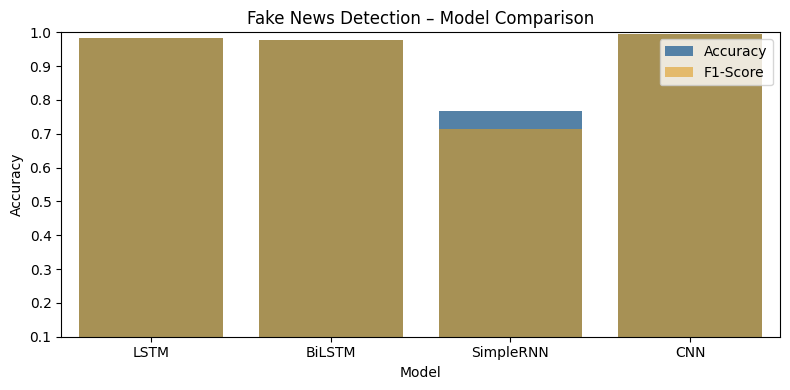

In [37]:
import pandas as pd, matplotlib.pyplot as plt, seaborn as sns

df = pd.read_csv('results/model_metrics_deep.csv')
print(df)

plt.figure(figsize=(8,4))
sns.barplot(x='Model', y='Accuracy', data=df, color='steelblue', label='Accuracy')
sns.barplot(x='Model', y='F1', data=df, color='orange', alpha=0.6, label='F1-Score')
plt.title('Fake News Detection – Model Comparison')
plt.ylim(0.1, 1.0)
plt.legend()
plt.tight_layout()
plt.show()


**Streamlit App for Interactive UI**

1. User inputs a news headline or paragraph.
2. Text is cleaned and converted to sequences using the tokenizer.
3. Each deep learning model (LSTM, BiLSTM, RNN, CNN) predicts Real/Fake.
4. Predictions and confidence are displayed; majority vote gives the final decision.


In [38]:
%%writefile app.py

import streamlit as st
st.set_page_config(page_title="Fake News Detection (Deep Learning)", page_icon="📰")

import re, os, joblib, numpy as np, tensorflow as tf
from tensorflow.keras.preprocessing.sequence import pad_sequences

# --------- CONFIG ----------
MODEL_DIR = "results/models/models"
MAX_LEN = 300
# ---------------------------

# ---------- TEXT CLEANER ----------
def clean_text(t):
    t = t.lower()
    t = re.sub(r"http\S+", "", t)
    t = re.sub(r"[^a-z\s]", "", t)
    t = re.sub(r"\s+", " ", t).strip()
    return t

# ---------- LOAD MODELS ----------
@st.cache_resource
def safe_load_model(names):
    for n in names:
        path = os.path.join(MODEL_DIR, n)
        if os.path.exists(path):
            return tf.keras.models.load_model(path, compile=False)
    return None

@st.cache_resource
def safe_joblib(name):
    path = os.path.join(MODEL_DIR, name)
    return joblib.load(path) if os.path.exists(path) else None

@st.cache_resource
def load_models():
    lstm_model   = safe_load_model(["lstm_model.keras", "lstm.h5"])
    bilstm_model = safe_load_model(["bilstm_model.keras"])
    rnn_model    = safe_load_model(["simplernn_model.keras"])
    cnn_model    = safe_load_model(["cnn_model.keras"])
    tokenizer    = safe_joblib("tokenizer.joblib")

    return lstm_model, bilstm_model, rnn_model, cnn_model, tokenizer

lstm_model, bilstm_model, rnn_model, cnn_model, tokenizer = load_models()

# ---------- PAGE HEADER ----------
st.title("📰 Fake News Detection Dashboard (Deep Learning)")
st.markdown(
    "This tool analyzes a given news headline or short paragraph "
    "using **multiple deep learning models (LSTM, BiLSTM, RNN, CNN)** "
    "to determine whether it’s **real or fake news**."
)

user_text = st.text_area(
    "Enter a news headline or paragraph:",
    height=160,
    placeholder="e.g. Sri Lanka central bank announces new monetary policy adjustments for 2025"
)
run = st.button("🔍 Detect")

# ---------- PREDICTION ----------
def predict_fake_news(text):
    results = {}
    text_cleaned = clean_text(text)

    def run_dl_model(model, name):
        if model is None or tokenizer is None:
            return
        seq = tokenizer.texts_to_sequences([text_cleaned])
        pad = pad_sequences(seq, maxlen=MAX_LEN)
        prob_fake = float(model.predict(pad, verbose=0)[0][0])
        pred = 1 if prob_fake >= 0.5 else 0
        results[name] = ("Fake" if pred else "Real", round(prob_fake, 3))

    # --- Run all available models ---
    run_dl_model(lstm_model, "LSTM")
    run_dl_model(bilstm_model, "BiLSTM")
    run_dl_model(rnn_model, "RNN")
    run_dl_model(cnn_model, "CNN")

    # --- Majority Vote ---
    votes = [label for label, _ in results.values()]
    final = "Fake" if votes.count("Fake") >= (len(votes)//2 + 1) else "Real"
    results["Majority_Vote"] = (final, None)
    return results

# ---------- DISPLAY RESULTS ----------
if run and user_text.strip():
    preds = predict_fake_news(user_text)

    st.subheader("Prediction Results")
    for model, (label, prob) in preds.items():
        if model != "Majority_Vote":
            st.write(f"**{model}:** {label}  |  Confidence = `{prob:.3f}`")

    st.markdown("---")
    final_label = preds["Majority_Vote"][0]
    if final_label == "Fake":
        st.error(f"🧾 **Final Decision:** {final_label}")
    else:
        st.success(f"🧾 **Final Decision:** {final_label}")

else:
    st.info("💡 Enter text above and click **Detect** to begin.")


Overwriting app.py


In [39]:
import os
os.environ["NGROK_API_KEY"] = "33sdEyTq9jF06Inp5UiZPbz2j4C_6kXyCb3f2Yy1Dp48hffih"


**Ngrok Setup and Public Link**

Install pyngrok - enables public tunnels.

Set API key - authenticates ngrok.

Kill old tunnels - avoid conflicts.

Start Streamlit - run app.py locally.

Open ngrok tunnel - make app accessible online.

In [ ]:
!pip -q install pyngrok==7.1.6

from pyngrok import ngrok
import subprocess, time, os

# If you have an ngrok API key, set it once; otherwise comment the next 2 lines.
NGROK_API_KEY = os.getenv("NGROK_API_KEY", None)
if not NGROK_API_KEY:
    print("If you have an ngrok API key, set it like this before running:")
    print("import os; os.environ['NGROK_API_KEY'] = 'YOUR_KEY_HERE'")

# Kill any previous tunnels
!pkill ngrok
ngrok.kill()


# Start Streamlit
port = 8501 # Reverting to the original port as changing it didn't resolve the issue
proc = subprocess.Popen(["streamlit", "run", "app.py",
                         "--server.port", str(port),
                         "--server.address", "0.0.0.0",
                         "--server.enableCORS", "false",
                         "--server.enableXsrfProtection", "false",
                         "--server.enablePooling", "true"]) # Add this line to enable pooling

# Give it a moment to boot
time.sleep(5)

# Open tunnel
if NGROK_API_KEY:
    ngrok.set_auth_token(NGROK_API_KEY)
public_url = ngrok.connect(port, "http", pooling_enabled=True).public_url # Added pooling_enabled=True
print("🔗 Public URL:", public_url)

In [41]:
!git add app.py
!git commit -m "added Streamlit app.py for final deployment"
!git push --set-upstream origin feat/evaluation

[feat/evaluation 5be45a9] added Streamlit app.py for final deployment
 1 file changed, 105 insertions(+), 107 deletions(-)
 rewrite app.py (66%)
Enumerating objects: 94, done.
Counting objects: 100% (73/73), done.
Delta compression using up to 2 threads
Compressing objects: 100% (28/28), done.
Writing objects: 100% (48/48), 27.90 KiB | 5.58 MiB/s, done.
Total 48 (delta 24), reused 40 (delta 18), pack-reused 0
remote: Resolving deltas: 100% (24/24), completed with 8 local objects.
To https://github.com/KavinMadusanka/fake-news-detection.git
   fadf48e..5be45a9  feat/evaluation -> feat/evaluation
Branch 'feat/evaluation' set up to track remote branch 'feat/evaluation' from 'origin'.
